In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Current agreed parameters

Pc = 30 * 1e5 # Chamber pressure
Pa = 1.1 * 1e5 # Ambient pressure
Dc = 109.49 / 1000 # Chamber Diamter
Lc = 254.16 / 1000 # Chamber length
Dt = 48.97 / 1000 # Throat diameter
ε = 4.3 # Expansion ratio
CR = 5 # Contraction ratio
F = 8000 # Target thrust

In [ ]:
# Calculate basic nozzle geometry

At = (math.pi * Dt**2) / 4 # Throat area
Ae = ε * At # Exit area # Exit area
De = math.sqrt((4 * Ae) / math.pi) # Exit diameter

print(f"Throat area = {At:.6f} m²")
print(f"Exit area = {Ae: .6f} m²")
print(f"Exit Diameter = {De * 1000: .6f} mm")

Throat area = 0.001883 m²
Exit area =  0.008099 m²
Exit Diameter =  101.546353 mm


In [ ]:
# Reference conical nozzle length (NASA Eq. 4-7)

Re = De / 2 # Exit radius
Rt = Dt/ 2 # Throat radius

alpha = math.radians(15) # 15 deg is used as a reference conical nozzle half-angle

R = 1.5 * Rt    # Reference throat curvature radius (NASA Eq. 4-7: 0.5-1.5 Rt;
                # upper limit selected, not optimised)


# The length of the conical nozzle section can be expressed by the equation:
L15 = (Rt * (math.sqrt(ε)-1) + R * (1/math.cos(alpha)-1)) / math.tan(alpha)

print(f"Reference conical nozzle length = {L15 * 1000: .2f} mm")

Reference conical nozzle length =  102.94 mm


In [ ]:
# Bell nozzle length (Diverging length) (NASA Rao parabolic approximation)
# Bell nozzle length is expressed as a fraction of the equivalent 15deg connical nozzle length (L15).

Lf = 0.8 # Fractional length

Lb = Lf * L15 # Bell nozzle length

print(f"Bell nozzle length = {Lb * 1000: .2f} mm")

Bell nozzle length =  82.36 mm


In [ ]:
# Rao parabolic bell nozzle contour (NASA Figure 4-14)

# Approximate wall angles from NASA chart (ε = 4.3, Lf = 80%)
theta_n = math.radians(22.5) # Initial wall angle
theta_e = math.radians(14) # Exit wall angle

print(f"Initial wall angle = {math.degrees(theta_n): .2f}°")
print(f"Exit wall angle = {math.degrees(theta_e): .2f}°")

Initial wall angle =  22.50°
Exit wall angle =  14.00°


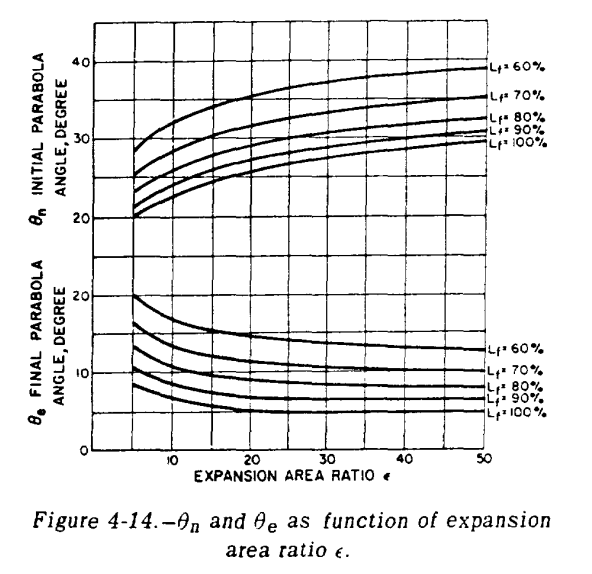

# NASA figure 4-14

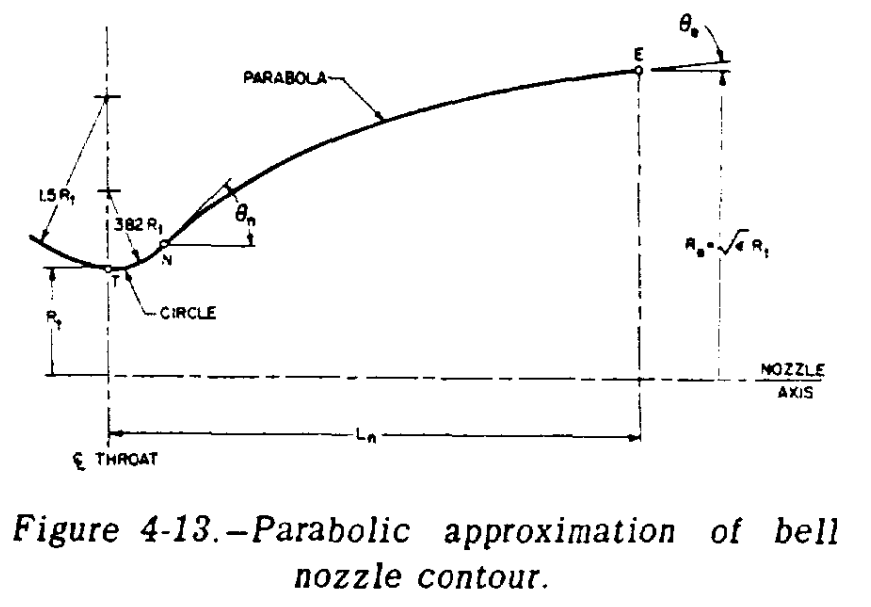

# NASA figure 4-13

In [ ]:
# Calculate Point N (where the throat section ends and the parabolic bell contour begins)
# Reference: NASA Figure 4-13

Rn = 0.382 * Rt # Divergent throat curvature radius

xN = Rn * math.sin(theta_n) # Axial coordinate
yN = Rt + Rn * (1 - math.cos(theta_n)) # Radial coordinate

print(f"Point N axial position = {xN * 1000: .2f} mm")
print(f"Point N radial position = {yN * 1000: .2f} mm")

Point N axial position =  3.58 mm
Point N radial position =  25.20 mm


In [ ]:
# Calculate Point E (nozzle exit)
# Reference: NASA Figure 4-13

xE = Lb # Axial position of nozzle exit
yE = De / 2 # Radial position nozzle exit

print(f"Point E axial position = {xE * 1000: .2f} mm")
print(f"Point E radial position = {yE * 1000: .2f} mm")

Point E axial position =  82.36 mm
Point E radial position =  50.77 mm


In [ ]:
# Calculate control point Q for the parabolic contour
# Based on tangent geometry in NASA 4-13

mn = math.tan(theta_n) # Initial wall slope
me = math.tan(theta_e) # Exit wall slope

# Intersection of the two tangent lines
xQ = (yE - yN + mn*xN - me*xE) / (mn - me)
yQ = yN + mn*(xQ - xN)

print(f"Control point Q axial position = {xQ * 1000: .2f} mm")
print(f"Control point Q radial position = {yQ * 1000: .2f} mm")

Control point Q axial position =  39.57 mm
Control point Q radial position =  40.11 mm


In [ ]:
# Generate parabolic bell nozzle contour
# Quadratic Bezier curve from N to E, controlled by Q

t = np.linspace(0, 1, 100) # 100 points along the curve

x = (1-t)**2*xN + 2*(1-t)*t*xQ + t**2*xE
y = (1-t)**2*yN + 2*(1-t)*t*yQ + t**2*yE

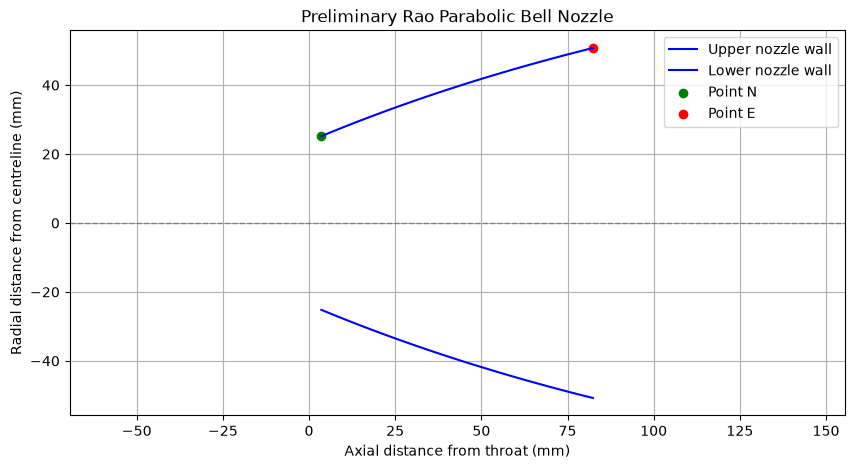

In [ ]:
# Plot the parabolic bell nozzle contour

plt.figure(figsize=(10, 5))

# Upper and lower nozzle walls
plt.plot(x *1000, y * 1000, 'b-', label="Upper nozzle wall")
plt.plot(x * 1000, -y * 1000, 'b-', label="Lower nozzle wall")

# Mark important points
plt.scatter([xN * 1000], [yN * 1000], color='green', label="Point N")
plt.scatter([xE * 1000], [yE *1000], color='red', label="Point E")

# Nozzle centreline
plt.axhline(0, color='gray', linestyle='--', linewidth=1)

plt.xlabel("Axial distance from throat (mm)")
plt.ylabel("Radial distance from centreline (mm)")
plt.title("Preliminary Rao Parabolic Bell Nozzle")

plt.axis('equal')
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# Circular throat transition (T to N)
# Reference: NASA Figure 4-13

phi = np.linspace(0, theta_n, 50)

x_arc = Rn * np.sin(phi) # Axial positions along the circular arc
y_arc = Rt + Rn * (1 - np.cos(phi)) # Radial positions along the circular arc

print(f"Throat position = (0.00, {Rt * 1000:.2f}) mm")
print(f"End of arc = ({x_arc[-1] * 1000:.2f}, {y_arc[-1] * 1000:.2f}) mm")

Throat position = (0.00, 24.48) mm
End of arc = (3.58, 25.20) mm


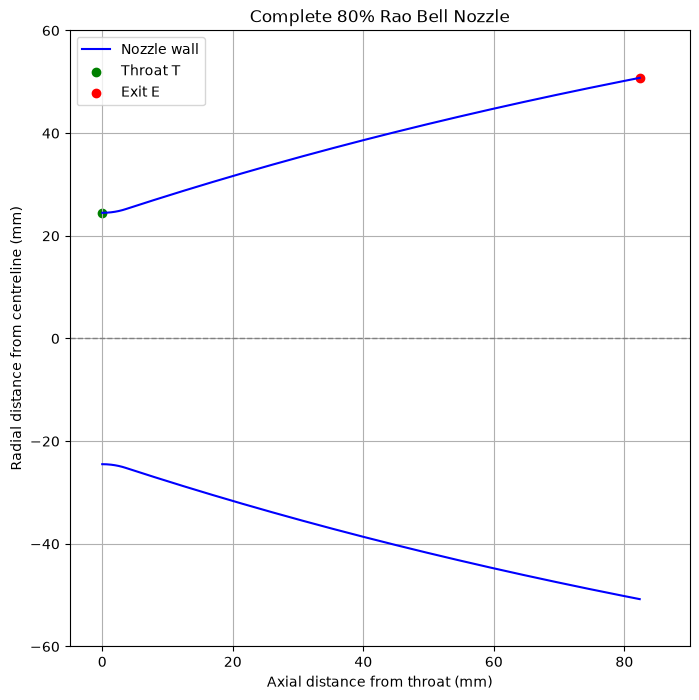

In [ ]:
# Combine circular arc and parabolic contour
# Reference: NASA Figure 4-13

x_full = np.concatenate((x_arc, x[1:])) # Combined axial positions
y_full = np.concatenate((y_arc, y[1:])) # Combined radial positions

# Plot complete divergent nozzle
plt.figure(figsize=(8, 8))

# Upper and lower nozzle walls
plt.plot(x_full * 1000, y_full * 1000, 'b-', label="Nozzle wall")
plt.plot(x_full * 1000, -y_full * 1000, 'b-')

# Mark throat and exit
plt.scatter(0, Rt * 1000, color='green', label="Throat T")
plt.scatter(xE * 1000, yE * 1000, color='red', label="Exit E")

# Nozzle centreline
plt.axhline(0, color='gray', linestyle='--', linewidth=1)

plt.xlabel("Axial distance from throat (mm)")
plt.ylabel("Radial distance from centreline (mm)")
plt.title("Complete 80% Rao Bell Nozzle")

plt.xlim(-5, 90)
plt.ylim(-60, 60)
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
# Verify whether the nozzle contour has correct dimensions

# Calculate dimensions from the generated contour
Dt_check = 2 * y_full[0] # Throat diameter
De_check = 2 * y_full[-1] # Exit diameter
Lb_check = x_full[-1] - x_full[0] # Divergent length

# Calculate expansion ratio
epsilon_check = (De_check / Dt_check)**2

print(f"Throat diameter = {Dt_check * 1000:.2f} mm")
print(f"Exit diameter = {De_check * 1000:.2f} mm")
print(f"Divergent length = {Lb_check * 1000:.2f} mm")
print(f"Expansion ratio = {epsilon_check:.2f}")

Throat diameter = 48.97 mm
Exit diameter = 101.55 mm
Divergent length = 82.36 mm
Expansion ratio = 4.30


In [ ]:
# Verify nozzle wall angles
# Tangent slopes of the quadratic Bezier curve

theta_n_check = math.degrees(math.atan2(yQ - yN, xQ - xN))
theta_e_check = math.degrees(math.atan2(yE - yQ, xE - xQ))

print(f"Initial wall angle = {theta_n_check:.2f}°")
print(f"Exit wall angle = {theta_e_check:.2f}°")

Initial wall angle = 22.50°
Exit wall angle = 14.00°
